Project Title

Loan Approval Prediction Using Machine Learning

Aim : The Project
To develop a machine learning model that predicts whether a loan application will be approved or rejected based on applicant details such as income, education, marital status, loan amount, credit history, and property area.

The project uses four machine learning algorithms:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)
The performance of these algorithms is compared using accuracy scores and a confusion matrix to identify the best-performing model.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [15]:
url = "https://raw.githubusercontent.com/2KRISHNAYADAV/Loan-Prediction-Dataset/main/loan_data_set.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print(df.head())
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural      

In [16]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

df = df.drop("Loan_ID", axis=1)

df = df.dropna(subset=["Loan_Status"])

X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"].map({"Y": 1, "N": 0})

print("\nFeatures:", X.shape)
print("Target:", y.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB
None

Missing Values:
Loan_ID               0
Gender               13
Married              

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (491, 11)
Testing Data: (123, 11)


In [18]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns

categorical_features = X.select_dtypes(include=["object"]).columns

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Data preprocessing completed!")

Data preprocessing completed!


In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC()
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy * 100
    })

    trained_models[name] = pipeline

    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

print("\nAll four algorithms trained successfully!")

Logistic Regression Accuracy: 86.18 %
Decision Tree Accuracy: 75.61 %
Random Forest Accuracy: 82.11 %
SVM Accuracy: 85.37 %

All four algorithms trained successfully!


             Algorithm   Accuracy
0  Logistic Regression  86.178862
3                  SVM  85.365854
2        Random Forest  82.113821
1        Decision Tree  75.609756


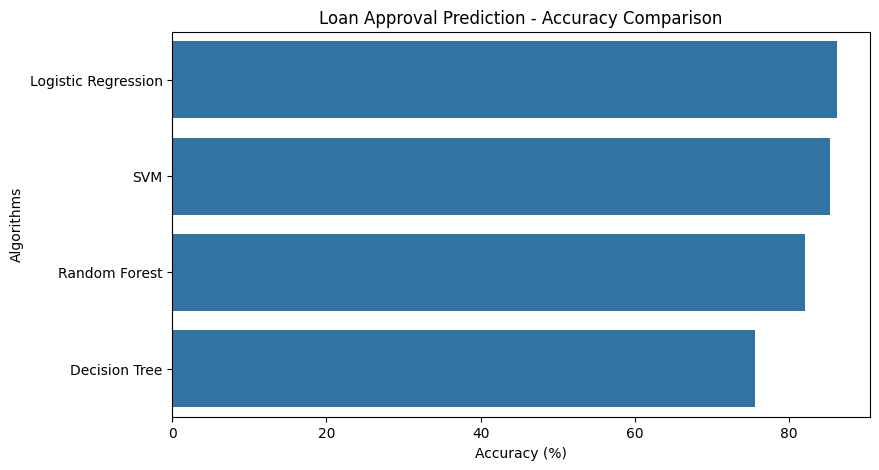

In [20]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print(results_df)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Algorithm"
)

plt.title("Loan Approval Prediction - Accuracy Comparison")
plt.xlabel("Accuracy (%)")
plt.ylabel("Algorithms")

plt.show()

Best Algorithm: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



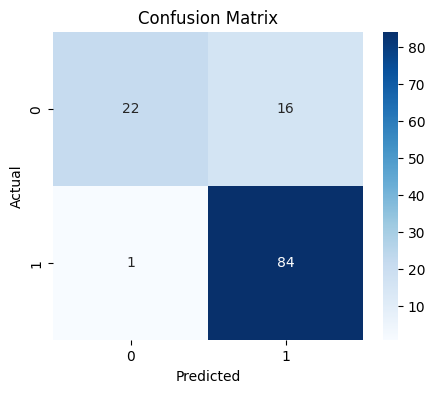

In [21]:
best_name = results_df.iloc[0]["Algorithm"]

best_model = trained_models[best_name]

y_pred = best_model.predict(X_test)

print("Best Algorithm:", best_name)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [22]:
new_applicant = pd.DataFrame([{
    "Gender": "Male",
    "Married": "Yes",
    "Dependents": "0",
    "Education": "Graduate",
    "Self_Employed": "No",
    "ApplicantIncome": 5000,
    "CoapplicantIncome": 2000,
    "LoanAmount": 150,
    "Loan_Amount_Term": 360,
    "Credit_History": 1.0,
    "Property_Area": "Urban"
}])

prediction = best_model.predict(new_applicant)

if prediction[0] == 1:
    print("Loan Approved")
else:
    print("Loan Not Approved")

Loan Approved


### Conclusion

The Loan Approval Prediction project was successfully implemented using Python and Machine Learning. Four algorithms  Logistic Regression, Decision Tree, Random Forest, and Support Vector Machine (SVM)  were applied to the dataset. Their performance was compared using accuracy scores and a confusion matrix. The best-performing model was used to predict the loan status of a sample applicant. The sample applicant was predicted as **Loan Approved**.